# Hotel Booking Cancellations & Revenue

I chose the Hotel Booking Demand dataset because I wanted a project that uses Python, SQL and Power BI together and also it’s a real-world dataset with a clear business question. I wanted to find out why bookings get cancelled and how much it could matter to a hotel, since a cancelled room is hard to plan around.

About the data:
- 119,390 rows, 32 columns, one row per booking. Two hotels (City and Resort), arrivals from July 2015 to August 2017.
- No booking ID and no payment data. That matters for duplicates and for revenue, so I deal with both below.
- `is_canceled = 1` includes no-shows as well as cancellations.

This notebook covers cleaning and EDA. The SQL queries and the Power BI dashboard are separate.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
import os

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110

BLUE, RED, GREY = '#3B6BA5', '#C0504D', '#A9B2BC'
os.makedirs('../reports/figures', exist_ok=True)

def save(fig, name):
    fig.tight_layout()
    fig.savefig(f'../reports/figures/{name}.png', dpi=130, bbox_inches='tight')
    plt.show()

## 1. Loading the data and first look

In [2]:
raw = pd.read_csv('../data/raw/hotel_bookings.csv')
print(raw.shape)
raw.head(3).T

(119390, 32)


,0,1,2
hotel,Resort Hotel,Resort Hotel,Resort Hotel
is_canceled,0,0,0
lead_time,342,737,7
arrival_date_year,2015,2015,2015
arrival_date_month,July,July,July
arrival_date_week_number,27,27,27
arrival_date_day_of_month,1,1,1
stays_in_weekend_nights,0,0,0
stays_in_week_nights,0,0,1
adults,2,2,1


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

119,390 rows and 32 columns. Types mostly look fine. Two things stand out: `children` is a float, which probably means it has missing values, and `reservation_status_date` is stored as text instead of a date.

## 2. Checking the raw data before touching it

In [4]:
# which columns have missing values?
missing = raw.isnull().sum() 
missing = missing[missing > 0].to_frame('missing')
missing['pct'] = (missing['missing'] / len(raw) * 100).round(2)
missing

,missing,pct
children,4,0.00
country,488,0.41
agent,16340,13.69
company,112593,94.31


`company` is about 94% empty and `agent` about 14%. I don't think these are errors: most bookings likely have no company, and a blank agent probably means the guest booked directly. I'll leave them as missing and add yes/no flags (`has_agent`, `has_company`) instead of filling in IDs. `country` (488) and `children` (4) are the real gaps.

In [5]:
# how many rows are exact copies of another row?
dup_mask = raw.duplicated()
print('identical rows:', dup_mask.sum(), f'({dup_mask.mean()*100:.1f}% of the file)')
print('cancel rate, non-duplicate rows (first copies):', round(raw[~dup_mask].is_canceled.mean()*100, 2))
print('cancel rate, flagged duplicate rows:', round(raw[dup_mask].is_canceled.mean()*100, 2))
print()
print('Market segment mix (% of rows)')
pd.concat({'duplicates': raw[dup_mask].market_segment.value_counts(normalize=True).mul(100).round(1),
           'others': raw[~dup_mask].market_segment.value_counts(normalize=True).mul(100).round(1)}, axis=1)

identical rows: 31994 (26.8% of the file)
cancel rate, non-duplicate rows (first copies): 27.49
cancel rate, flagged duplicate rows: 63.13

Market segment mix (% of rows)


,duplicates,others
market_segment,,
Groups,46.5,5.7
Offline TA/TO,32.3,15.9
Online TA,15.2,59.1
Corporate,3.4,4.8
Direct,2.5,13.5
Complementary,0.1,0.8
Aviation,0.0,0.3
Undefined,NaN,0.0


31,994 rows (about 27% of the file) are exact copies of another row, and they cancel much more often (63% against 27% for the other rows), mostly in Groups and Offline TA/TO. There's no booking ID, so I can't tell if they're the same booking entered twice or separate bookings with identical details. Deleting them would be a guess, so I keep all rows and add a flag, `is_duplicate_row`, so they can be filtered out later. This is a limitation: if they are real duplicates, the overall cancellation rate would be about 27.5% instead of 37%.

In [6]:
# looking at negative, zero and very high ADR
print('ADR min / max:', raw.adr.min(), '/', raw.adr.max())
print('negative ADR rows:', (raw.adr < 0).sum())
print('ADR = 0 rows:', (raw.adr == 0).sum())
print()
print('Five highest ADR values:', raw.adr.sort_values().tail(5).tolist())
print()
print('ADR = 0 by market segment:')
print(raw[raw.adr == 0].market_segment.value_counts().head(5))
print('average ADR before cleaning:', round(raw.adr.mean(), 2))

ADR min / max: -6.38 / 5400.0
negative ADR rows: 1
ADR = 0 rows: 1959

Five highest ADR values: [450.0, 451.5, 508.0, 510.0, 5400.0]

ADR = 0 by market segment:
market_segment
Complementary    680
Online TA        367
Offline TA/TO    332
Groups           252
Direct           240
Name: count, dtype: int64
average ADR before cleaning: 101.83


That average ADR can't be trusted yet. There's one negative value, one 5,400 (the next highest is 510), and almost 2,000 zeros. About a third of the zeros are Complementary bookings, which makes sense, but the rest aren't obviously free stays. I'll sort this out in the cleaning section.

In [7]:
# checking zero guests and zero nights
guests = raw.adults + raw.children.fillna(0) + raw.babies
nights = raw.stays_in_weekend_nights + raw.stays_in_week_nights
print('zero guests:', (guests == 0).sum())
print('zero adults:', (raw.adults == 0).sum())
print('zero nights:', (nights == 0).sum())
print('zero guests AND zero nights:', ((guests == 0) & (nights == 0)).sum())
print()
print('Looking at the extreme party sizes:')
raw[(raw.adults >= 10) | (raw.children >= 5) | (raw.babies >= 5)][
    ['hotel','is_canceled','adults','children','babies','market_segment','customer_type','adr','lead_time','reservation_status']]

zero guests: 180
zero adults: 403
zero nights: 715
zero guests AND zero nights: 70

Looking at the extreme party sizes:


,hotel,is_canceled,adults,children,babies,market_segment,customer_type,adr,lead_time,reservation_status
328,Resort Hotel,1,2,10.0,0,Offline TA/TO,Contract,133.16,55,No-Show
1539,Resort Hotel,1,40,0.0,0,Direct,Group,0.00,304,Canceled
1587,Resort Hotel,1,26,0.0,0,Offline TA/TO,Group,0.00,333,Canceled
1643,Resort Hotel,1,50,0.0,0,Direct,Group,0.00,336,Canceled
1752,Resort Hotel,1,26,0.0,0,Offline TA/TO,Group,0.00,340,Canceled
1884,Resort Hotel,1,26,0.0,0,Offline TA/TO,Group,0.00,347,Canceled
1917,Resort Hotel,1,27,0.0,0,Direct,Group,0.00,349,Canceled
1962,Resort Hotel,1,27,0.0,0,Direct,Group,0.00,352,Canceled
2003,Resort Hotel,1,26,0.0,0,Offline TA/TO,Group,0.00,354,Canceled
2164,Resort Hotel,1,26,0.0,0,Offline TA/TO,Group,0.00,361,Canceled


There are 180 bookings with zero guests and 715 with zero nights, and a few rows with very big parties (for example 10 to 55 adults, all Group bookings that were cancelled). They are a tiny part of the data, so I keep them and only add flags (`zero_guests`, `zero_stay_nights`, `extreme_guest_count`).

In [8]:
for c in ['meal', 'market_segment', 'distribution_channel']:
    print(c, '-> Undefined rows:', (raw[c] == 'Undefined').sum())
print()
print('is_repeated_guest = 1 but no previous bookings at all:',
      ((raw.is_repeated_guest == 1) & (raw.previous_cancellations + raw.previous_bookings_not_canceled == 0)).sum())
print('is_repeated_guest = 0 but has previous bookings:',
      ((raw.is_repeated_guest == 0) & (raw.previous_cancellations + raw.previous_bookings_not_canceled > 0)).sum())

meal -> Undefined rows: 1169
market_segment -> Undefined rows: 2
distribution_channel -> Undefined rows: 5

is_repeated_guest = 1 but no previous bookings at all: 590
is_repeated_guest = 0 but has previous bookings: 6237


The repeat guest flag doesn't match the previous-booking columns, in both directions: 590 rows are flagged repeat with no previous bookings, and 6,237 have previous bookings but aren't flagged. I can't tell which column is right, so I leave both and treat anything about repeat guests as approximate.

In [9]:
# does reservation_status just repeat is_canceled?
pd.crosstab(raw.reservation_status, raw.is_canceled)

is_canceled,0,1
reservation_status,,
Canceled,0,43017
Check-Out,75166,0
No-Show,0,1207


`reservation_status` just repeats the outcome: Check-Out is always 0, and Canceled and No-Show are always 1. So I don't use it to explain cancellations, only to mark the no-shows. Note that `is_canceled = 1` includes no-shows, so "cancelled" in this project means cancelled or no-show.

In [10]:
# which months does each year cover?
coverage = raw.groupby(['arrival_date_year', 'arrival_date_month']).size().unstack(0)
months = ['January','February','March','April','May','June','July','August','September','October','November','December']
coverage.reindex(months)

arrival_date_year,2015,2016,2017
arrival_date_month,,,
January,NaN,2248.0,3681.0
February,NaN,3891.0,4177.0
March,NaN,4824.0,4970.0
April,NaN,5428.0,5661.0
May,NaN,5478.0,6313.0
June,NaN,5292.0,5647.0
July,2776.0,4572.0,5313.0
August,3889.0,5063.0,4925.0
September,5114.0,5394.0,NaN


Arrivals run from July 2015 to August 2017. So 2015 only covers July to December, 2017 only covers January to August, and 2016 is the only full year. Because of that, comparing yearly totals would be misleading, so I don't do it.

## 3. Cleaning

I'm working on a copy, so `raw` stays untouched.

In [11]:
df = raw.copy()

# flag the extra copies of identical rows (the first copy isn't flagged)
df['is_duplicate_row'] = raw.duplicated().astype(int)
print('flagged duplicates:', df.is_duplicate_row.sum())

flagged duplicates: 31994


One row has an ADR of -6.38. A price can't be negative, so I'm dropping that row.

The 4 missing `children` values become 0, since all four bookings have two or more adults and no babies. Missing `country` becomes "Unknown" instead of being dropped, because those bookings cancel at only about 14%, which is quite different from the rest. Agent and company stay missing, and I add yes/no flags for them.

I'm also renaming "Undefined" to "Unknown" so it matches the missing-country label in charts. These rows stay visible instead of being dropped.

In [12]:
print(df[df.adr < 0][['hotel', 'is_canceled', 'lead_time', 'adr', 'market_segment']])
df = df[df.adr >= 0].copy()
print('rows now:', len(df))
print("\n")
df['children'] = df['children'].fillna(0).astype(int)
df['country'] = df['country'].fillna('Unknown')
df['has_agent'] = df['agent'].notna().astype(int)
df['has_company'] = df['company'].notna().astype(int)
print(df[['children', 'country']].isnull().sum())
print("\n")
for c in ['meal', 'market_segment', 'distribution_channel']:
    df[c] = df[c].replace('Undefined', 'Unknown')
df.market_segment.value_counts()

              hotel  is_canceled  lead_time   adr market_segment
14969  Resort Hotel            0        195 -6.38         Groups
rows now: 119389


children    0
country     0
dtype: int64




market_segment
Online TA        56477
Offline TA/TO    24219
Groups           19810
Direct           12606
Corporate         5295
Complementary      743
Aviation           237
Unknown              2
Name: count, dtype: int64

Year, month name and day are in separate columns, so I build one arrival date from them and convert the status date to a date too. I'm also adding an estimated booking date (arrival minus lead time).

In [13]:
# build one arrival date from year, month name and day
month_map = {m: i for i, m in enumerate(months, start=1)}
df['arrival_month_num'] = df['arrival_date_month'].map(month_map)
df['arrival_date'] = pd.to_datetime(dict(year=df['arrival_date_year'],
                                         month=df['arrival_month_num'],
                                         day=df['arrival_date_day_of_month']))
df['arrival_year_month'] = df['arrival_date'].dt.strftime('%Y-%m')   # used later for monthly charts
df['reservation_status_date'] = pd.to_datetime(df['reservation_status_date'])
# booking date is a guess: arrival minus lead time
df['estimated_booking_date'] = df['arrival_date'] - pd.to_timedelta(df['lead_time'], unit='D')
df[['arrival_date', 'lead_time', 'estimated_booking_date', 'reservation_status_date']].head()

,arrival_date,lead_time,estimated_booking_date,reservation_status_date
0,2015-07-01,342,2014-07-24,2015-07-01
1,2015-07-01,737,2013-06-24,2015-07-01
2,2015-07-01,7,2015-06-24,2015-07-02
3,2015-07-01,13,2015-06-18,2015-07-02
4,2015-07-01,14,2015-06-17,2015-07-03


New columns I added:

| Column | How it's calculated |
|---|---|
| `total_guests` | adults + children + babies |
| `total_stay_nights` | stays_in_weekend_nights + stays_in_week_nights |
| `estimated_booking_value` | `adr_clean` x `total_stay_nights` |
| `lead_time_bucket` | 0-7, 8-30, 31-90, 91-180, 181-365, 365+ days |

`estimated_booking_value` is only an estimate: ADR x nights is what the booking would be worth if the stay happened at that rate. It isn't money the hotel received. For a cancelled booking it's potential value, not a confirmed loss, because the data has no payments, refunds or cancellation fees, and doesn't say if the room was resold.

In [14]:
df['total_guests'] = df['adults'] + df['children'] + df['babies']
df['total_stay_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']

# flags instead of deleting: 1 = yes, 0 = no
df['zero_guests'] = (df['total_guests'] == 0).astype(int)
df['zero_stay_nights'] = (df['total_stay_nights'] == 0).astype(int)
df['adr_zero'] = (df['adr'] == 0).astype(int)
df['adr_outlier'] = (df['adr'] > 1000).astype(int)   # only the 5,400 booking
df['extreme_guest_count'] = ((df['adults'] >= 10) | (df['children'] >= 5) | (df['babies'] >= 5)).astype(int)
df['is_no_show'] = (df['reservation_status'] == 'No-Show').astype(int)
df['room_changed'] = (df['reserved_room_type'] != df['assigned_room_type']).astype(int)

print(df[['zero_guests', 'zero_stay_nights', 'adr_zero', 'adr_outlier', 'extreme_guest_count', 'is_no_show']].sum())

zero_guests             180
zero_stay_nights        715
adr_zero               1959
adr_outlier               1
extreme_guest_count      16
is_no_show             1207
dtype: int64


The booking with ADR 5,400 stays in the booking and cancellation counts, since it's a real (cancelled) booking. I blank its ADR in a new column `adr_clean` so it doesn't distort ADR averages or booking-value totals. Rows with ADR = 0 also stay in the counts, but I leave them out of average ADR (using the `adr_zero` flag), because free stays would pull the average down.

In [15]:
# the one very high ADR row
print(df[df.adr_outlier == 1][['hotel', 'is_canceled', 'lead_time', 'market_segment', 'total_stay_nights', 'adr']])

df['adr_clean'] = df['adr'].where(df['adr_outlier'] == 0)
df['estimated_booking_value'] = (df['adr_clean'] * df['total_stay_nights']).round(2)

# how much did the cleaning change the average ADR?
print('average ADR (raw):                  ', round(raw.adr.mean(), 2))
print('average ADR (outlier out):          ', round(df.adr_clean.mean(), 2))
print('average ADR (outlier + zeros out):  ', round(df[df.adr_zero == 0].adr_clean.mean(), 2))

            hotel  is_canceled  lead_time market_segment  total_stay_nights     adr
48515  City Hotel            1         35  Offline TA/TO                  1  5400.0
average ADR (raw):                   101.83
average ADR (outlier out):           101.79
average ADR (outlier + zeros out):   103.49


In [16]:
# group lead time into buckets (the -1 makes sure 0 days falls in the first bucket)
bins = [-1, 7, 30, 90, 180, 365, 10000]
labels = ['0-7 days', '8-30 days', '31-90 days', '91-180 days', '181-365 days', '365+ days']
df['lead_time_bucket'] = pd.cut(df['lead_time'], bins=bins, labels=labels).astype(str)
# a number for each bucket so Power BI can sort them in order
df['lead_time_bucket_order'] = pd.cut(df['lead_time'], bins=bins, labels=range(1, 7)).astype(int)
df['lead_time_bucket'].value_counts().reindex(labels)

lead_time_bucket
0-7 days        19746
8-30 days       18960
31-90 days      29553
91-180 days     26439
181-365 days    21543
365+ days        3148
Name: count, dtype: int64

Zero-night bookings should have a value of 0 (ADR x 0), so I check that, and also that no rows went missing along the way.

In [17]:
# sanity checks before saving the cleaned file
print('zero-night rows with non-zero value:', ((df.zero_stay_nights == 1) & (df.estimated_booking_value > 0)).sum())
print('rows: raw', len(raw), '-> cleaned', len(df), '(removed:', len(raw) - len(df), ')')
print('is_canceled values:', df.is_canceled.value_counts().to_dict())
print('missing in key columns:', df[['is_canceled','hotel','lead_time','adr_clean']].isnull().sum().to_dict())

zero-night rows with non-zero value: 0
rows: raw 119390 -> cleaned 119389 (removed: 1 )
is_canceled values: {0: 75165, 1: 44224}
missing in key columns: {'is_canceled': 0, 'hotel': 0, 'lead_time': 0, 'adr_clean': 1}


In [18]:
# columns to keep in the cleaned file (the original columns plus the ones I added)
out_cols = ['hotel', 'is_canceled', 'is_no_show', 'lead_time', 'lead_time_bucket', 'lead_time_bucket_order',
            'arrival_date', 'arrival_date_year', 'arrival_month_num', 'arrival_date_month', 'arrival_year_month',
            'arrival_date_week_number', 'arrival_date_day_of_month', 'estimated_booking_date',
            'stays_in_weekend_nights', 'stays_in_week_nights', 'total_stay_nights',
            'adults', 'children', 'babies', 'total_guests',
            'meal', 'country', 'market_segment', 'distribution_channel',
            'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled',
            'reserved_room_type', 'assigned_room_type', 'room_changed', 'booking_changes',
            'deposit_type', 'agent', 'company', 'has_agent', 'has_company',
            'days_in_waiting_list', 'customer_type', 'adr', 'adr_clean', 'adr_zero', 'adr_outlier',
            'estimated_booking_value', 'required_car_parking_spaces', 'total_of_special_requests',
            'reservation_status', 'reservation_status_date',
            'zero_guests', 'zero_stay_nights', 'extreme_guest_count', 'is_duplicate_row']
cleaned = df[out_cols].copy()

# dates as plain YYYY-MM-DD text so SQL and Power BI read them cleanly
for c in ['arrival_date', 'estimated_booking_date', 'reservation_status_date']:
    cleaned[c] = cleaned[c].dt.strftime('%Y-%m-%d')

cleaned.to_csv('../data/cleaned/hotel_bookings_cleaned.csv', index=False)
print(cleaned.shape)   # should be 119389 rows, 52 columns

(119389, 52)


## 4. KPIs

I'm using the same KPI definitions in Python, SQL and Power BI so the numbers match.

| KPI | Definition |
|---|---|
| Total Bookings | Number of rows |
| Cancelled Bookings | Rows with `is_canceled = 1` (cancellations and no-shows) |
| Confirmed Bookings | Rows with `is_canceled = 0` |
| Cancellation Rate | Cancelled Bookings / Total Bookings |
| Average ADR | Mean of `adr_clean`, leaving out `adr_zero = 1` rows (and the one blanked outlier) |
| Average Lead Time | Mean of `lead_time` in days |
| Average Stay Length | Mean of `total_stay_nights`, leaving out zero-night bookings |
| Estimated Booking Value | Sum of `adr_clean` x `total_stay_nights` |
| Estimated Revenue at Risk | Estimated Booking Value of rows with `is_canceled = 1` |
| Repeat Guest % | Rows with `is_repeated_guest = 1` / Total Bookings (approximate, because the flag is unreliable) |
| Average Special Requests | Mean of `total_of_special_requests` |

Estimated Revenue at Risk is not the hotel's actual loss. It's what the cancelled bookings would have been worth at their recorded ADR, and the data can't show if a cancelled room was resold.

In [19]:
# one function so I can calculate the KPIs for all bookings and for each hotel
def kpis(d):
    adr_rows = d[d.adr_zero == 0]
    stay_rows = d[d.zero_stay_nights == 0]
    value = d.estimated_booking_value.sum()
    risk = d.loc[d.is_canceled == 1, 'estimated_booking_value'].sum()
    return pd.Series({
        'Total Bookings': len(d),
        'Cancelled Bookings': int(d.is_canceled.sum()),
        'Confirmed Bookings': int((d.is_canceled == 0).sum()),
        'Cancellation Rate %': round(d.is_canceled.mean() * 100, 2),
        'Average ADR': round(adr_rows.adr_clean.mean(), 2),
        'Average Lead Time (days)': round(d.lead_time.mean(), 1),
        'Average Stay Length (nights)': round(stay_rows.total_stay_nights.mean(), 2),
        'Estimated Booking Value': round(value, 0),
        'Estimated Revenue at Risk': round(risk, 0),
        'Revenue at Risk % of Value': round(risk / value * 100, 2),
        'Repeat Guest %': round(d.is_repeated_guest.mean() * 100, 2),
        'Average Special Requests': round(d.total_of_special_requests.mean(), 2),
    })

# KPIs for the whole file, then for each hotel side by side
kpi_table = pd.concat({'All hotels': kpis(df),
                       'City Hotel': kpis(df[df.hotel == 'City Hotel']),
                       'Resort Hotel': kpis(df[df.hotel == 'Resort Hotel'])}, axis=1)
kpi_table

,All hotels,City Hotel,Resort Hotel
Total Bookings,119389.00,79330.00,40059.00
Cancelled Bookings,44224.00,33102.00,11122.00
Confirmed Bookings,75165.00,46228.00,28937.00
Cancellation Rate %,37.04,41.73,27.76
Average ADR,103.49,106.87,96.77
Average Lead Time (days),104.00,109.70,92.70
Average Stay Length (nights),3.45,2.99,4.36
Estimated Booking Value,42718161.00,25274070.00,17444091.00
Estimated Revenue at Risk,16721837.00,10879660.00,5842177.00
Revenue at Risk % of Value,39.14,43.05,33.49


44,224 of 119,389 bookings (37.04%) are cancelled or no-shows. The estimated value attached to them is about 16.72 million out of 42.72 million (39.1%). The dataset doesn't give a currency, so I'm leaving the unit off.

## 5. Exploratory analysis

I go through one question at a time, each with a chart or table and a short note:

1. How many bookings are cancelled, and does it differ by hotel?
2. Do cancellations change by month?
3. Which market segment cancels the most?
4. Which distribution channel cancels the most?
5. Does deposit type matter?
6. Which customer type cancels the most?
7. Do bookings made far in advance cancel more?
8. Which countries do the cancellations come from?
9. How much estimated revenue is at risk?
10. How does the average price (ADR) differ by room type?
11. How long do guests stay, and does it matter for cancellations?

These are comparisons of rates. They show which groups cancel more, not why.

### Q1. How many bookings are cancelled, and does it differ by hotel?

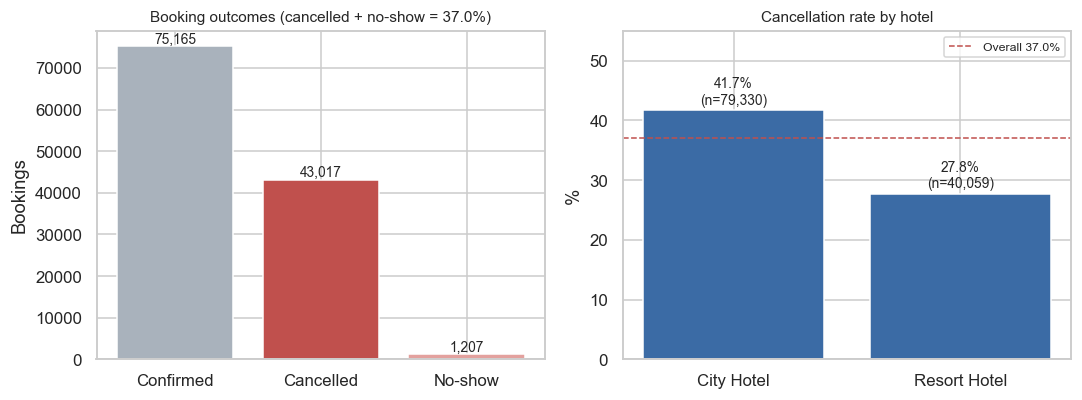

,bookings,cancelled,rate
hotel,,,
City Hotel,79330,33102,41.726963
Resort Hotel,40059,11122,27.764048


In [20]:
overall_rate = df.is_canceled.mean() * 100
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))

# left chart: confirmed vs cancelled vs no-show
outcome = pd.Series({'Confirmed': (df.is_canceled == 0).sum(),
                     'Cancelled': ((df.is_canceled == 1) & (df.is_no_show == 0)).sum(),
                     'No-show': df.is_no_show.sum()})
axes[0].bar(outcome.index, outcome.values, color=[GREY, RED, '#E3A19E'])
for i, v in enumerate(outcome.values):
    axes[0].text(i, v + 800, f'{v:,}', ha='center', fontsize=9)
axes[0].set_title(f'Booking outcomes (cancelled + no-show = {overall_rate:.1f}%)', fontsize=10)
axes[0].set_ylabel('Bookings')

# right chart: cancellation rate for each hotel
h = df.groupby('hotel')['is_canceled'].agg(bookings='size', cancelled='sum', rate='mean')
h['rate'] *= 100
axes[1].bar(h.index, h['rate'], color=BLUE)
axes[1].axhline(overall_rate, color=RED, ls='--', lw=1, label=f'Overall {overall_rate:.1f}%')
for i, (r, n) in enumerate(zip(h['rate'], h['bookings'])):
    axes[1].text(i, r + 1, f'{r:.1f}%\n(n={n:,})', ha='center', fontsize=9)
axes[1].set_ylim(0, 55)
axes[1].set_title('Cancellation rate by hotel', fontsize=10)
axes[1].set_ylabel('%')
axes[1].legend(fontsize=8)
save(fig, '01_overall_and_hotel')
h

City Hotel is at 41.73% against 27.76% for Resort Hotel. It has 66% of all bookings but 75% of all cancellations. Only 1,207 of the cancelled bookings are no-shows.

### Q2. Do cancellations change by month?

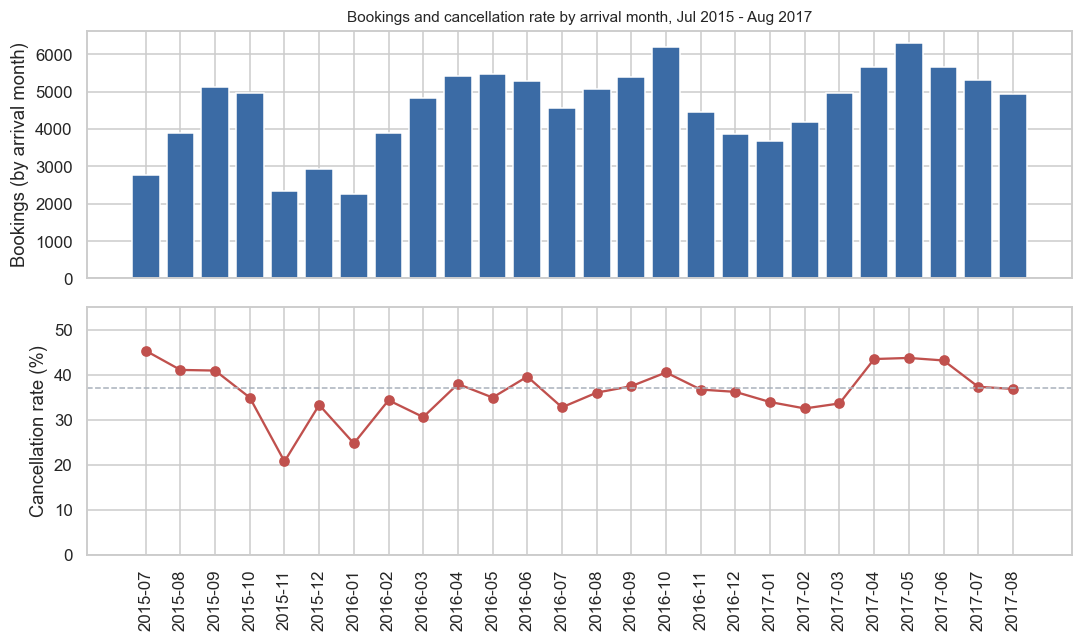

lowest monthly rate : 2015-11 20.8
highest monthly rate: 2015-07 45.4
fewest bookings in a month: 2016-01 2248
most bookings in a month : 2017-05 6313

month 07 {'2015-07': 45.4, '2016-07': 32.8, '2017-07': 37.3}
month 08 {'2015-08': 41.1, '2016-08': 36.0, '2017-08': 36.9}
month 09 {'2015-09': 40.9, '2016-09': 37.5}
month 10 {'2015-10': 34.9, '2016-10': 40.5}
month 11 {'2015-11': 20.8, '2016-11': 36.7}
month 12 {'2015-12': 33.3, '2016-12': 36.2}


In [21]:
# monthly bookings and cancellation rate
ym = df.groupby('arrival_year_month')['is_canceled'].agg(bookings='size', cancelled='sum', rate='mean')
ym['rate'] *= 100

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].bar(ym.index, ym.bookings, color=BLUE)
axes[0].set_ylabel('Bookings (by arrival month)')
axes[0].set_title('Bookings and cancellation rate by arrival month, Jul 2015 - Aug 2017', fontsize=10)
axes[1].plot(ym.index, ym.rate, marker='o', color=RED)
axes[1].axhline(overall_rate, color=GREY, ls='--', lw=1)
axes[1].set_ylabel('Cancellation rate (%)')
axes[1].set_ylim(0, 55)
axes[1].tick_params(axis='x', rotation=90)
save(fig, '02_timeline')
print('lowest monthly rate :', ym.rate.idxmin(), round(ym.rate.min(), 1))
print('highest monthly rate:', ym.rate.idxmax(), round(ym.rate.max(), 1))
print('fewest bookings in a month:', ym.bookings.idxmin(), ym.bookings.min())
print('most bookings in a month :', ym.bookings.idxmax(), ym.bookings.max())
print()
# does the same calendar month behave the same in different years?
for m in ['07', '08', '09', '10', '11', '12']:
    print('month', m, ym[ym.index.str.endswith('-' + m)].rate.round(1).to_dict())

Monthly bookings range from 2,248 (January 2016) to 6,313 (May 2017). The cancellation rate swings between 20.8% (November 2015) and 45.4% (July 2015). The same month isn't the same each year (July is 45.4% in 2015, 32.8% in 2016 and 37.3% in 2017), so I can't say summer is riskier. The data also starts and ends mid-year, so I wouldn't read too much into the monthly pattern.

### Q3. Which market segment cancels the most?

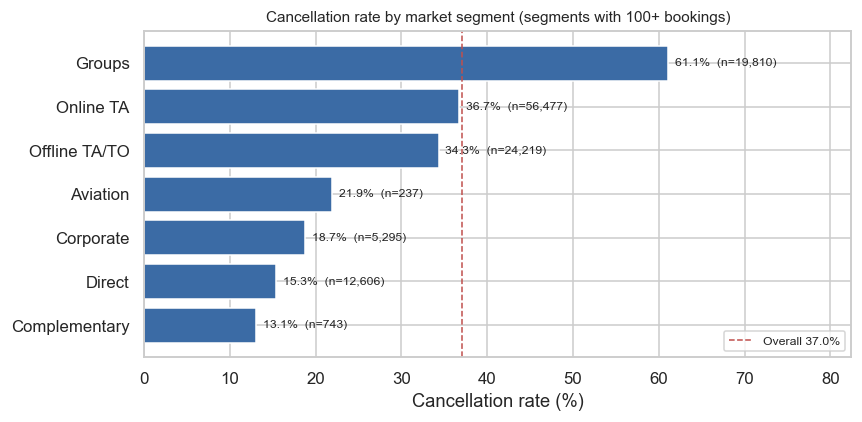

,bookings,cancelled,rate
market_segment,,,
Unknown,2,2,100.00
Groups,19810,12097,61.07
Online TA,56477,20739,36.72
Offline TA/TO,24219,8311,34.32
Aviation,237,52,21.94
Corporate,5295,992,18.73
Direct,12606,1934,15.34
Complementary,743,97,13.06


In [22]:
# bookings, cancelled and rate for any column
def rate_table(data, col, min_n=0):
    t = data.groupby(col)['is_canceled'].agg(bookings='size', cancelled='sum', rate='mean')
    t['rate'] = (t['rate'] * 100).round(2)
    return t[t['bookings'] >= min_n]   # min_n hides groups that are too small

# horizontal bar chart of the rates from rate_table
def rate_bars(t, title, fname, ref=None, figsize=(8, 4)):
    t = t.sort_values('rate')
    fig, ax = plt.subplots(figsize=figsize)
    ax.barh(t.index.astype(str), t['rate'], color=BLUE)
    for y, (r, n) in enumerate(zip(t['rate'], t['bookings'])):
        ax.text(r + 0.8, y, f'{r:.1f}%  (n={n:,})', va='center', fontsize=8)
    if ref is not None:
        ax.axvline(ref, color=RED, ls='--', lw=1, label=f'Overall {ref:.1f}%')
        ax.legend(fontsize=8, loc='lower right')
    ax.set_xlim(0, max(t['rate']) * 1.35)
    ax.set_xlabel('Cancellation rate (%)')
    ax.set_title(title, fontsize=10)
    save(fig, fname)

seg = rate_table(df, 'market_segment')
rate_bars(seg[seg.bookings >= 100], 'Cancellation rate by market segment (segments with 100+ bookings)', '04_segment', ref=overall_rate)
seg.sort_values('rate', ascending=False)

In [23]:
# the Groups number looked high, so checking what's inside it
print(pd.crosstab(df.market_segment, df.deposit_type))
print()
nodep = df[df.deposit_type == 'No Deposit']
print('Same table, bookings with No Deposit only:')
rate_table(nodep, 'market_segment').sort_values('rate', ascending=False)

deposit_type    No Deposit  Non Refund  Refundable
market_segment                                    
Aviation               237           0           0
Complementary          743           0           0
Corporate             4957         334           4
Direct               12581          19           6
Groups               10508        9172         130
Offline TA/TO        19209        5006           4
Online TA            56403          56          18
Unknown                  2           0           0

Same table, bookings with No Deposit only:


,bookings,cancelled,rate
market_segment,,,
Unknown,2,2,100.00
Online TA,56403,20668,36.64
Groups,10508,2974,28.30
Aviation,237,52,21.94
Offline TA/TO,19209,3306,17.21
Direct,12581,1916,15.23
Corporate,4957,679,13.70
Complementary,743,97,13.06


Groups has the highest rate (61.07%), then Online TA (36.72%) and Offline TA/TO (34.32%). Direct (15.34%) and Corporate (18.73%) are much lower. Online TA is also by far the biggest segment: 56,477 bookings (47% of the file) and 20,739 cancellations.

Groups looked too high, so I checked what's inside it. Almost half of Groups (9,172 of 19,810) is Non Refund bookings, which cancel at about 99% (see Q5). For No Deposit bookings only, Groups drops to 28.3% and Online TA is the highest at 36.6%. So Groups is high mainly because of the Non Refund bookings, while Online TA is high either way.

### Q4. Which distribution channel cancels the most?

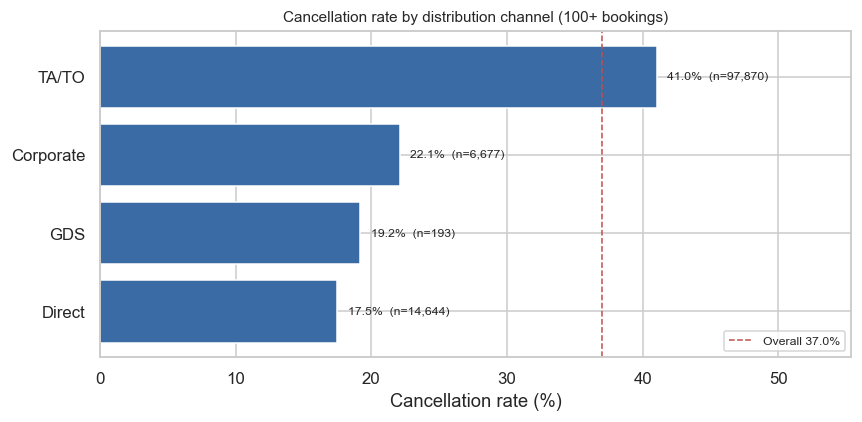

,bookings,cancelled,rate
distribution_channel,,,
Unknown,5,4,80.00
TA/TO,97870,40152,41.03
Corporate,6677,1474,22.08
GDS,193,37,19.17
Direct,14644,2557,17.46


In [24]:
# cancellation rate by distribution channel
ch = rate_table(df, 'distribution_channel')
rate_bars(ch[ch.bookings >= 100], 'Cancellation rate by distribution channel (100+ bookings)', '05_channel', ref=overall_rate)
ch.sort_values('rate', ascending=False)

TA/TO bookings (travel agents and tour operators) cancel at 41.03% and make up 82% of all bookings. Direct is 17.46% and Corporate 22.08%. GDS is small (193 bookings). Guests booking through agents cancel much more than guests booking directly, but the data has no cancellation terms, so I can't say why.

### Q5. Does deposit type matter?

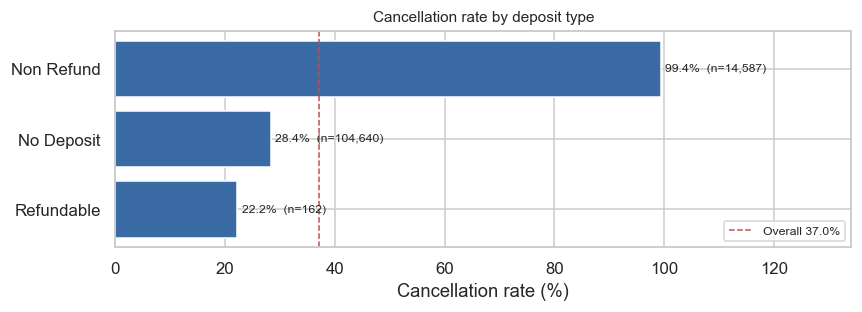

              bookings  cancelled   rate
deposit_type                            
No Deposit      104640      29694  28.38
Non Refund       14587      14494  99.36
Refundable         162         36  22.22

Non Refund bookings by country (top 3): {'PRT': 14176, 'GBR': 138, 'ESP': 131}
Non Refund share of all cancelled bookings: 32.8 %
Cancellation rate without Non Refund bookings: 28.37 %
Non Refund rows after removing duplicates: 1038  rate: 94.7 %


In [25]:
# cancellation rate by deposit type
dep = rate_table(df, 'deposit_type')
rate_bars(dep, 'Cancellation rate by deposit type', '06_deposit', ref=overall_rate, figsize=(8, 3))
print(dep)
print()
# looking at the Non Refund group more closely
nr = df[df.deposit_type == 'Non Refund']
print('Non Refund bookings by country (top 3):', nr.country.value_counts().head(3).to_dict())
print('Non Refund share of all cancelled bookings:', round(nr.is_canceled.sum() / df.is_canceled.sum() * 100, 1), '%')
print('Cancellation rate without Non Refund bookings:', round(df[df.deposit_type != 'Non Refund'].is_canceled.mean() * 100, 2), '%')
print('Non Refund rows after removing duplicates:', len(nr[nr.is_duplicate_row == 0]),
      ' rate:', round(nr[nr.is_duplicate_row == 0].is_canceled.mean() * 100, 2), '%')

Non Refund bookings are cancelled 99.36% of the time (14,587 bookings). No Deposit is 28.38% and Refundable 22.22% (only 162 bookings). Non Refund bookings are almost all from Portugal (14,176 of 14,587) and make up about 33% of all cancelled bookings.

This looks wrong, because a guest on a non-refundable rate has the most reason not to cancel. It could be how the deposit type was recorded, but I can't tell from this file, so I'm reporting the number as it is and not basing any recommendation on it.

### Q6. Which customer type cancels the most?

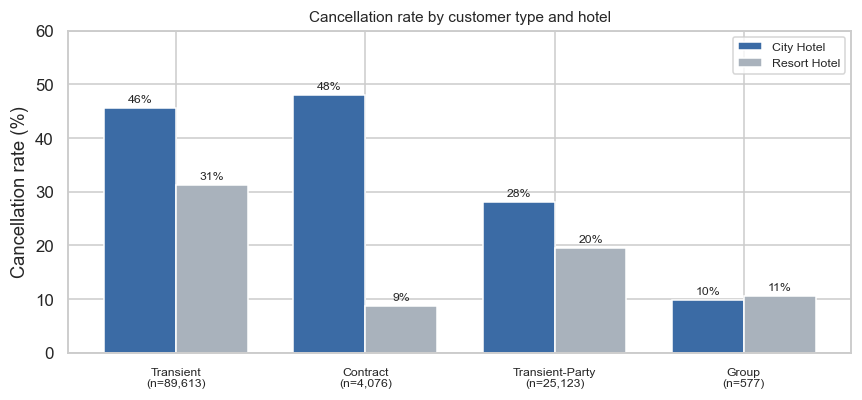

hotel            City Hotel  Resort Hotel
customer_type                            
Contract               48.0           8.8
Group                   9.9          10.6
Transient              45.6          31.2
Transient-Party        28.1          19.5



,bookings,cancelled,rate
customer_type,,,
Transient,89613,36514,40.75
Contract,4076,1262,30.96
Transient-Party,25123,6389,25.43
Group,577,59,10.23


In [26]:
ct_hotel = (df.groupby(['customer_type', 'hotel'])['is_canceled'].mean().unstack() * 100).round(1)
ct = rate_table(df, 'customer_type')

fig, ax = plt.subplots(figsize=(8, 3.8))
order = ['Transient', 'Contract', 'Transient-Party', 'Group']
x = np.arange(len(order)); w = 0.38
ax.bar(x - w/2, ct_hotel.loc[order, 'City Hotel'], w, color=BLUE, label='City Hotel')
ax.bar(x + w/2, ct_hotel.loc[order, 'Resort Hotel'], w, color=GREY, label='Resort Hotel')
for i, o in enumerate(order):
    ax.text(i - w/2, ct_hotel.loc[o, 'City Hotel'] + 1, f"{ct_hotel.loc[o, 'City Hotel']:.0f}%", ha='center', fontsize=8)
    ax.text(i + w/2, ct_hotel.loc[o, 'Resort Hotel'] + 1, f"{ct_hotel.loc[o, 'Resort Hotel']:.0f}%", ha='center', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels([f"{o}\n(n={ct.loc[o,'bookings']:,})" for o in order], fontsize=8)
ax.set_ylabel('Cancellation rate (%)'); ax.set_ylim(0, 60); ax.legend(fontsize=8)
ax.set_title('Cancellation rate by customer type and hotel', fontsize=10)
save(fig, '07_customer_type')
print(ct_hotel)
print()
ct.sort_values('rate', ascending=False)

Transient guests (75% of bookings) cancel the most at 40.75%, then Contract (30.96%), Transient-Party (25.43%) and Group (10.23%, only 577 bookings). Contract bookings cancel at 48.0% in City Hotel but only 8.8% in Resort Hotel.

### Q7. Do bookings made far in advance cancel more?

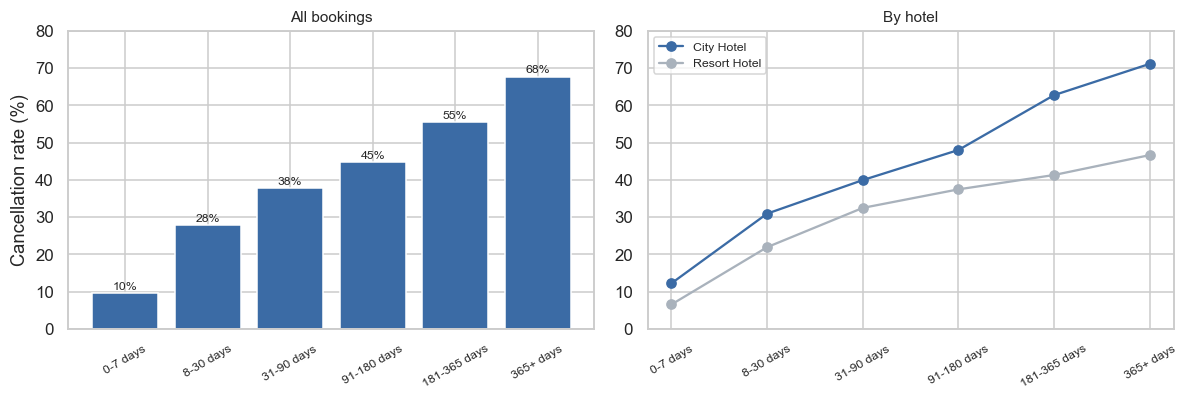

                  bookings  cancelled   rate
lead_time_bucket                            
0-7 days             19746       1902   9.63
8-30 days            18960       5283  27.86
31-90 days           29553      11141  37.70
91-180 days          26439      11821  44.71
181-365 days         21543      11947  55.46
365+ days             3148       2130  67.66

Average lead time (days): cancelled vs confirmed
              mean  median
is_canceled               
0             80.0    45.0
1            144.8   113.0

No Deposit only - rate by lead time bucket:


,bookings,cancelled,rate
lead_time_bucket,,,
0-7 days,19619,1798,9.16
8-30 days,18438,4802,26.04
31-90 days,27139,8736,32.19
91-180 days,22260,7760,34.86
181-365 days,15904,6334,39.83
365+ days,1280,264,20.62


In [27]:
lt = rate_table(df, 'lead_time_bucket').reindex(labels)
lt_hotel = (df.groupby(['lead_time_bucket', 'hotel'])['is_canceled'].mean().unstack().reindex(labels) * 100)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(lt.index, lt.rate, color=BLUE)
for i, (r, n) in enumerate(zip(lt.rate, lt.bookings)):
    axes[0].text(i, r + 1, f'{r:.0f}%', ha='center', fontsize=8)
axes[0].set_ylim(0, 80); axes[0].set_ylabel('Cancellation rate (%)')
axes[0].set_title('All bookings', fontsize=10); axes[0].tick_params(axis='x', labelsize=8, rotation=30)

lt_hotel.plot(ax=axes[1], marker='o', color=[BLUE, GREY])
axes[1].set_ylim(0, 80); axes[1].set_title('By hotel', fontsize=10)
axes[1].set_xlabel(''); axes[1].tick_params(axis='x', labelsize=8, rotation=30); axes[1].legend(fontsize=8)
save(fig, '08_lead_time')

print(lt)
print()
print('Average lead time (days): cancelled vs confirmed')
print(df.groupby('is_canceled').lead_time.agg(['mean', 'median']).round(1))
print()
print('No Deposit only - rate by lead time bucket:')
rate_table(nodep, 'lead_time_bucket').reindex(labels)

The cancellation rate goes up with every lead-time step, from 9.6% for bookings made within a week of arrival to 67.7% for bookings made over a year ahead. Cancelled bookings were made 145 days ahead on average (median 113) vs 80 days (median 45) for confirmed ones. It's the same pattern in both hotels.

One catch: for No Deposit bookings only, the 365+ group drops to 20.6%, so the very high 365+ number is partly the Non Refund bookings.

This is the clearest pattern I found. It makes sense that plans change more the further away the stay is.

### Q8. Which countries do the cancellations come from?

Small countries with only a handful of bookings can easily hit 100% cancellation, so a plain ranking by rate would be mostly noise. For rates I'm only using countries with at least 1,000 bookings, and I show volume separately.

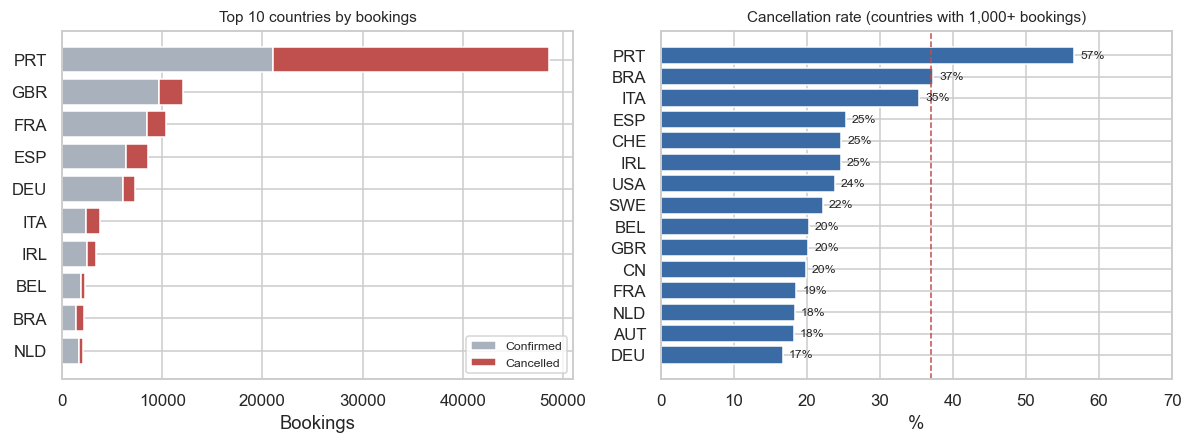

Top 10 by cancelled bookings:


,bookings,cancelled,rate
country,,,
PRT,48590,27519,56.64
GBR,12128,2453,20.23
ESP,8568,2177,25.41
FRA,10415,1934,18.57
ITA,3766,1333,35.40
DEU,7287,1218,16.71
IRL,3375,832,24.65
BRA,2224,830,37.32
USA,2097,501,23.89


In [28]:
cty = rate_table(df, 'country')
top10 = cty.sort_values('bookings', ascending=False).head(10)
big = cty[cty.bookings >= 1000].sort_values('rate')

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
t = top10.sort_values('bookings')
axes[0].barh(t.index, t.bookings - t.cancelled, color=GREY, label='Confirmed')
axes[0].barh(t.index, t.cancelled, left=t.bookings - t.cancelled, color=RED, label='Cancelled')
axes[0].set_title('Top 10 countries by bookings', fontsize=10)
axes[0].set_xlabel('Bookings'); axes[0].legend(fontsize=8, loc='lower right')
axes[1].barh(big.index, big.rate, color=BLUE)
axes[1].axvline(overall_rate, color=RED, ls='--', lw=1)
for y, (r, n) in enumerate(zip(big.rate, big.bookings)):
    axes[1].text(r + 0.8, y, f'{r:.0f}%', va='center', fontsize=8)
axes[1].set_title('Cancellation rate (countries with 1,000+ bookings)', fontsize=10)
axes[1].set_xlabel('%'); axes[1].set_xlim(0, 70)
save(fig, '09_countries')

print('Top 10 by cancelled bookings:')
cty.sort_values('cancelled', ascending=False).head(10)

In [29]:
prt = df[df.country == 'PRT']
print('PRT share of bookings:', round(len(prt) / len(df) * 100, 1), '%')
print('PRT share of cancelled bookings:', round(prt.is_canceled.sum() / df.is_canceled.sum() * 100, 1), '%')
print('Cancellation rate, PRT:', round(prt.is_canceled.mean() * 100, 2), '| all other countries:', round(df[df.country != 'PRT'].is_canceled.mean() * 100, 2))
print('PRT, No Deposit only:', round(prt[prt.deposit_type == 'No Deposit'].is_canceled.mean() * 100, 2))
print()
print('Non-PRT bookings: cancellation rate by market segment')
rate_table(df[df.country != 'PRT'], 'market_segment').sort_values('rate', ascending=False)

PRT share of bookings: 40.7 %
PRT share of cancelled bookings: 62.2 %
Cancellation rate, PRT: 56.64 | all other countries: 23.59
PRT, No Deposit only: 38.86

Non-PRT bookings: cancellation rate by market segment


,bookings,cancelled,rate
market_segment,,,
Online TA,44495,15312,34.41
Direct,6756,727,10.76
Complementary,78,8,10.26
Aviation,132,11,8.33
Groups,5917,423,7.15
Corporate,1187,34,2.86
Offline TA/TO,12234,190,1.55


Portugal (PRT) is by far the biggest source: 48,590 bookings (41%) and 27,519 cancellations, which is 62% of all cancellations. Its rate is 56.6%, against 23.6% for all other countries combined. The next biggest markets (GBR, FRA, ESP, DEU) sit at 17-25%. Among countries with 1,000+ bookings, Brazil (37%) and Italy (35%) come next after Portugal.

Some of Portugal's number comes from the Non Refund bookings (almost all of them are from Portugal, see Q5), but PRT with No Deposit only is still 38.9%, which is higher than other countries. With Portugal removed, Online TA is still the main source of cancellations (34.4%) and most other segments drop to single digits or low teens. So the Online TA problem isn't just a Portugal effect.

### Q9. How much estimated revenue is at risk?

In [30]:
# share of the estimated revenue at risk by market segment
risk = df[df.is_canceled == 1].groupby('market_segment').estimated_booking_value.sum()
print((risk / risk.sum() * 100).round(1).sort_values(ascending=False))

market_segment
Online TA        61.2
Groups           16.7
Offline TA/TO    14.9
Direct            5.9
Corporate         1.2
Aviation          0.1
Complementary     0.0
Unknown           0.0
Name: estimated_booking_value, dtype: float64


Estimated Revenue at Risk is about 16.72 million out of 42.72 million (39.1%). It's higher at City Hotel (43% of its value) than at Resort Hotel (33.5%). By market segment, Online TA bookings are 61.2% of the revenue at risk, Groups 16.7% and Offline TA/TO 14.9%. These are estimates (ADR x nights), not real losses.

### Q10. How does the average price (ADR) differ by room type?

In [31]:
# average ADR by room type, only room types with at least 300 bookings
adr = df[df.adr_zero == 0]
rt = adr.groupby(['hotel', 'reserved_room_type']).adr_clean.agg(['mean', 'count']).reset_index()
rt = rt[rt['count'] >= 300]

print("Average ADR")
print(rt.pivot(index='reserved_room_type', columns='hotel', values='mean').round(1))
print()
print("Number of bookings")
print(rt.pivot(index='reserved_room_type', columns='hotel', values='count'))

Average ADR
hotel               City Hotel  Resort Hotel
reserved_room_type                          
A                         97.6          77.9
B                         93.1           NaN
C                          NaN         164.2
D                        132.8         104.7
E                        161.7         116.0
F                        192.7         137.9
G                        228.2         171.7
H                          NaN         190.1

Number of bookings
hotel               City Hotel  Resort Hotel
reserved_room_type                          
A                      61683.0       22889.0
B                       1082.0           NaN
C                          NaN         902.0
D                      11652.0        7353.0
E                       1506.0        4917.0
F                       1759.0        1065.0
G                        428.0        1578.0
H                          NaN         595.0


Room A is booked the most in both hotels (61,683 bookings in City Hotel and 22,889 in Resort Hotel).

Later room letters mostly cost more, but not always. In City Hotel, B is the cheapest (93.1) and G is the most expensive (228.2). In Resort Hotel, A is the cheapest (77.9) and H is the most expensive (190.1). Room C in Resort Hotel (164.2) costs more than D, E and F. I haven't looked into why.

For the room types both hotels have, City Hotel costs more than Resort Hotel every time.

I left out bookings with ADR 0 and room types with fewer than 300 bookings in a hotel.

### Q11. How long do guests stay, and does it matter for cancellations?

In [32]:
# group stays into the same buckets I use in Power BI
bins = [-1, 0, 1, 3, 7, 1000]
stay_labels = ['0 nights', '1 night', '2-3 nights', '4-7 nights', '8+ nights']
stay_bucket = pd.cut(df['total_stay_nights'], bins=bins, labels=stay_labels)

stay = df.groupby(stay_bucket, observed=True)['is_canceled'].agg(['size', 'sum', 'mean'])
stay.columns = ['bookings', 'cancelled', 'rate']
stay['rate'] = (stay['rate'] * 100).round(2)
stay

,bookings,cancelled,rate
total_stay_nights,,,
0 nights,715,35,4.90
1 night,21020,5271,25.08
2-3 nights,54719,23514,42.97
4-7 nights,37679,13525,35.90
8+ nights,5256,1879,35.75


Most bookings are for 2-3 nights: 54,719 bookings, about 46% of the total. Then 4-7 nights (37,679) and 1 night (21,020).

Cancellations don't just keep going up with longer stays. Leaving out 0 nights, 1 night has the lowest rate (25.08%) and 2-3 nights has the highest (42.97%). After that it falls to 35.90% for 4-7 nights and 35.75% for 8+ nights.

0 nights has only 715 bookings and a 4.90% rate, so I'm not reading much into it.

I haven't checked why 2-3 nights cancels the most.

## 6. Saving the data to SQLite

The SQL part of the project runs on this cleaned dataset. I used SQLite because it needs no server and works on any laptop. The queries are standard SQL, so they should run with few changes in MySQL or PostgreSQL.

In [33]:
conn = sqlite3.connect('../data/cleaned/hotel_bookings.db')
cleaned.to_sql('hotel_bookings', conn, if_exists='replace', index=False)

# quick check that SQL and pandas agree
q = '''
SELECT COUNT(*) AS total_bookings,
       SUM(is_canceled) AS cancelled,
       ROUND(100.0 * SUM(is_canceled) / COUNT(*), 2) AS cancel_rate
FROM hotel_bookings
'''
print(pd.read_sql(q, conn))
print('pandas:', len(df), int(df.is_canceled.sum()), round(df.is_canceled.mean() * 100, 2))
conn.close()

   total_bookings  cancelled  cancel_rate
0          119389      44224        37.04
pandas: 119389 44224 37.04


## 7. What I found and what I'd suggest

What I found:

- About 37% of bookings (44,224 of 119,389) are cancelled or no-shows. City Hotel is higher (41.7%) than Resort Hotel (27.8%).
- About 16.72 million of the 42.72 million estimated booking value (39.1%) is estimated revenue at risk. It is 43% at City Hotel and 33.5% at Resort Hotel.
- Cancellation goes up with lead time, from 9.6% for bookings made within a week of arrival to 67.7% for bookings made over a year ahead. The 365+ group is partly Non Refund bookings (for No Deposit only it is 20.6%).
- Online TA has the most cancelled bookings (20,739) and about 61% of the estimated revenue at risk. Even without Portugal its rate is 34.4%. TA/TO bookings cancel much more than Direct bookings (41.0% vs 17.5%).
- Groups has the highest rate (61.1%), but almost half of Groups bookings are Non Refund.
- Portugal has 41% of bookings and 62% of cancellations.
- 2-3 night stays have the highest cancellation rate (43.0%) and 1 night stays the lowest (25.1%, leaving out the very small 0 night group).
- Non Refund bookings cancel about 99% of the time. I can't explain it with this data, so I didn't base any suggestion on it.

What I'd suggest (these are ideas, I haven't tested them):

1. Keep a closer eye on bookings made far in advance, for example with a reminder or reconfirmation closer to arrival, since they cancel the most.
2. Look at the cancellation terms with Online TA partners, since that segment has most of the revenue at risk. Direct bookings cancel less, so it could be worth checking whether more direct bookings would help.
3. Plan for more cancellations at City Hotel than at Resort Hotel when forecasting occupancy.

Limitations:

- There is no booking ID, so I can't tell if the 31,994 identical rows are real duplicates. Without them the cancellation rate would be about 27.5%.
- There is no payment or refund data, so ADR x nights is only an estimate.
- `is_canceled` includes no-shows.
- 2015 and 2017 are partial years.
- These are patterns in one dataset. They don't show why guests cancel.

The SQL queries are in the `sql/` folder and the Power BI dashboard is in `powerbi/`.